# Matrix factorization comparison

Gradient descent, alternating gradient, LeAP-SSN, and GLAd-SSN ($p=0.2,0.5$).
The Newton methods use either the exact generalized Hessian or Gauss–Newton (GN).

With $U\in\mathbb{R}^{m\times r}$ and $V\in\mathbb{R}^{r\times n}$,
$$F(U,V)=\frac12\|UV-M\|_F^2
  +\frac{\alpha}{2}(\|U\|_F^2+\|V\|_F^2)
  +\frac{\beta}{2}(\|(-U)_+\|_F^2+\|(-V)_+\|_F^2).$$

This single-seed comparison uses the corrected oracle and revised equation (27).
It is separate from the multi-seed figures in
[the paper](https://arxiv.org/abs/2602.08069), Section 5.2 / Appendix E.2.

In [1]:
import sys
from pathlib import Path

sys.dont_write_bytecode = True
MF_DIR = Path.cwd()
if not (MF_DIR / "oracles_mat_fac.py").exists():
    MF_DIR = MF_DIR / "MF"
if not (MF_DIR / "oracles_mat_fac.py").exists():
    raise FileNotFoundError("Run from the repository root or the MF folder.")
MF_DIR = MF_DIR.resolve()
sys.path.insert(0, str(MF_DIR))
OUTPUT_DIR = MF_DIR / "comparison_results"


import contextlib
import hashlib
import io
import json
import platform
import warnings
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from threadpoolctl import threadpool_info, threadpool_limits

from methods import gradient_method, alternating_gradient_method, mf_leapssn, mf_gladssn
from oracles_mat_fac import PositiveMatrixFactorization
from utils import plot_mf_comparison

%matplotlib inline

## Settings

All methods share the data, initial factors, and iteration cap. Newton variants
share the **initial trial shift** $\lambda_0$ and MINRES settings; curvature is
refreshed every iteration. GLAd internally sets $\Lambda_0=\lambda_0/\|g_0\|^p$.
GN retains ridge and penalty curvature, giving $H_{\rm GN}\succeq\alpha I$.
MINRES is retained for both curvature choices to isolate their effect.

Runs use fixed budgets, with gradient and objective tolerances disabled;
Newton methods can exit earlier at an exactly zero gradient or on failure.
`iterations_exceeded` means the budget was used. Equal iteration counts do
not imply equal work; alternating iterations include both block updates.

In [2]:
config = dict(
    seed=0, m=200, n=100, r=12, noise=0.0,  # Additive noise standard deviation.
    alpha=0.01, beta=200.0, max_outer_iterations=1000,
    glad_exponents=[0.2, 0.5], initial_lambda=1024.0,
    lss_method="minres", lss_tol=1e-9, lss_maxiters=400,
    blas_threads=1, lazy_hessians=False, grad_tol=None, f_star=None,
)

environment = dict(
    python=sys.version, numpy=np.__version__, scipy=scipy.__version__,
    platform=platform.platform(), processor=platform.processor(), precision="float64",
    created_utc=datetime.now(timezone.utc).isoformat(),
    source_sha256={name: hashlib.sha256((MF_DIR / name).read_bytes()).hexdigest()
                   for name in ("oracles_mat_fac.py", "methods.py", "oracles.py", "utils.py")},
)

In [3]:
# Preserve the original random draws, including the draw when noise is zero.
rng = np.random.RandomState(config["seed"])
m, n, r = config["m"], config["n"], config["r"]
U_true = rng.rand(m, r)
V_true = rng.rand(n, r).T
M_clean = U_true @ V_true
M_obs = M_clean + config["noise"] * rng.randn(m, n)
initial_values = 0.5 * rng.randn((m + n) * r)
U_0 = initial_values[:m*r].reshape(m, r)
V_0 = initial_values[m*r:].reshape(n, r).T

oracle = PositiveMatrixFactorization(M_obs, r, alpha=config["alpha"], beta=config["beta"])
x_0 = oracle.pack(U_0, V_0)
print(f"{m} x {n}, rank {r}, seed {config['seed']}; initial F = {oracle.func(x_0):.3f}")

200 x 100, rank 12, seed 0; initial F = 149673.864


## Run comparison

The table reports the full objective, full gradient norm, weighted nonnegativity
penalty, and runtime. A small gradient alone does not establish a good solution.
MINRES uses an internal stopping criterion; a finite result at its iteration
cap still faces the outer acceptance tests. Solver messages are saved with the results.

In [4]:
budget = config["max_outer_iterations"]
newton_options = dict(
    n_iters=budget, H_0=config["initial_lambda"], grad_tol=config["grad_tol"],
    f_star=config["f_star"], lazy_Hessians=config["lazy_hessians"], warnings=True,
    lss_method=config["lss_method"], lss_tol=config["lss_tol"],
    lss_maxiters=config["lss_maxiters"],
)
methods_to_run = {
    "Gradient descent": (gradient_method, dict(max_iter=budget, warnings=True)),
    "Alternating gradient": (alternating_gradient_method,
                             dict(max_iter=budget, tol=None, warnings=True)),
}
styles = {
    "Gradient descent": dict(color="#E8601C", linestyle="-"),
    "Alternating gradient": dict(color="#C64B83", linestyle="-"),
}
families = [("LeAP-SSN", mf_leapssn, {}, "#27272A")]
for p, color in zip(config["glad_exponents"], plt.get_cmap("viridis")(
        np.linspace(0.2, 0.65, len(config["glad_exponents"])))):
    families.append((f"GLAd p={p:g}", mf_gladssn, dict(p=p), color.tolist()))

for family, solver, options, color in families:
    for curvature, use_gn, line in [("exact", False, "-"), ("GN", True, "--")]:
        label = f"{family} ({curvature})"
        methods_to_run[label] = (solver, dict(newton_options, **options, use_gauss_newton=use_gn))
        styles[label] = dict(color=color, linestyle=line)

In [5]:
histories, solutions, solver_logs, runtime_warnings = {}, {}, {}, {}
rows = []
with threadpool_limits(limits=config["blas_threads"]):
    environment["active_threadpools"] = threadpool_info()
    # Warm up both curvature operators outside solver timings.
    oracle.func(x_0)
    oracle.grad(x_0)
    for curvature in (oracle.hess, oracle.hess_gn):
        curvature(x_0)(np.ones_like(x_0))

    for label, (solver, options) in methods_to_run.items():
        print(f"Running {label}...", flush=True)
        log = io.StringIO()
        with warnings.catch_warnings(record=True) as caught, contextlib.redirect_stdout(log):
            warnings.simplefilter("always", RuntimeWarning)
            z, status, history = solver(oracle, x_0.copy(), **options)
        solver_logs[label] = log.getvalue()
        runtime_warnings[label] = [str(w.message) for w in caught]
        histories[label], solutions[label] = dict(history), z

        # Check the recorded endpoint against the returned factors.
        objective = float(oracle.func(z))
        gradient_norm = float(np.linalg.norm(oracle.grad(z)))
        np.testing.assert_allclose(history["func"][-1], objective, rtol=1e-11, atol=1e-11)
        np.testing.assert_allclose(history["grad_norm"][-1], gradient_norm, rtol=1e-10, atol=1e-10)
        if not np.all(np.isfinite(z)):
            raise RuntimeError(f"Nonfinite final factors: {label}")
        rows.append(dict(method=label, iterations=len(history["func"])-1,
                         objective=objective, gradient_norm=gradient_norm,
                         penalty=float(oracle.penalty(z)),
                         runtime_seconds=float(history["time"][-1]), status=status))
        if caught or "W:" in log.getvalue():
            print(f"  Solver warnings recorded for {label}; see results.json.")

summary = pd.DataFrame(rows).set_index("method")
display(summary.style.format({"objective": "{:.6f}", "gradient_norm": "{:.3e}",
                              "penalty": "{:.3e}", "runtime_seconds": "{:.2f}"}))

Running Gradient descent...


Running Alternating gradient...


Running LeAP-SSN (exact)...


Running LeAP-SSN (GN)...


Running GLAd p=0.2 (exact)...


Running GLAd p=0.2 (GN)...


Running GLAd p=0.5 (exact)...


Running GLAd p=0.5 (GN)...


,iterations,objective,gradient_norm,penalty,runtime_seconds,status
method,,,,,,
Gradient descent,1000,11.286457,3.110e+00,3.117e-01,0.26,iterations_exceeded
Alternating gradient,1000,9.144918,6.833e-01,2.058e-01,0.50,iterations_exceeded
LeAP-SSN (exact),1000,5.703000,1.480e-03,9.234e-05,44.15,iterations_exceeded
LeAP-SSN (GN),1000,5.704877,2.105e-03,1.358e-04,39.03,iterations_exceeded
GLAd p=0.2 (exact),1000,5.703216,1.144e-03,8.666e-05,45.92,iterations_exceeded
GLAd p=0.2 (GN),1000,5.722953,4.465e-03,4.935e-04,42.51,iterations_exceeded
GLAd p=0.5 (exact),1000,5.712844,1.537e-03,3.140e-04,45.15,iterations_exceeded
GLAd p=0.5 (GN),1000,5.701660,2.537e-03,5.183e-05,37.85,iterations_exceeded


In [6]:
def numpy_to_json(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"Cannot serialize {type(value).__name__}")

OUTPUT_DIR.mkdir(exist_ok=True)
factor_keys = {label: f"method_{i}" for i, label in enumerate(solutions)}
results = dict(config=config, environment=environment, styles=styles,
               histories=histories, summary=rows, factor_keys=factor_keys,
               solver_logs=solver_logs, runtime_warnings=runtime_warnings)
(OUTPUT_DIR / "results.json").write_text(
    json.dumps(results, indent=2, default=numpy_to_json, allow_nan=False), encoding="utf-8")
np.savez_compressed(OUTPUT_DIR / "final_factors.npz", x_0=x_0,
                    **{factor_keys[label]: z for label, z in solutions.items()})
print("Saved results and final factors to comparison_results/.")

Saved results and final factors to comparison_results/.


## Plots

Solid Newton curves use exact curvature; dashed curves use Gauss–Newton.
All recorded iterates are shown. JSON, final factors, and PNG/SVG figures are
saved in `comparison_results/`. Use `plot_matrix_factorization_comparison.ipynb`
to replot without rerunning the methods.

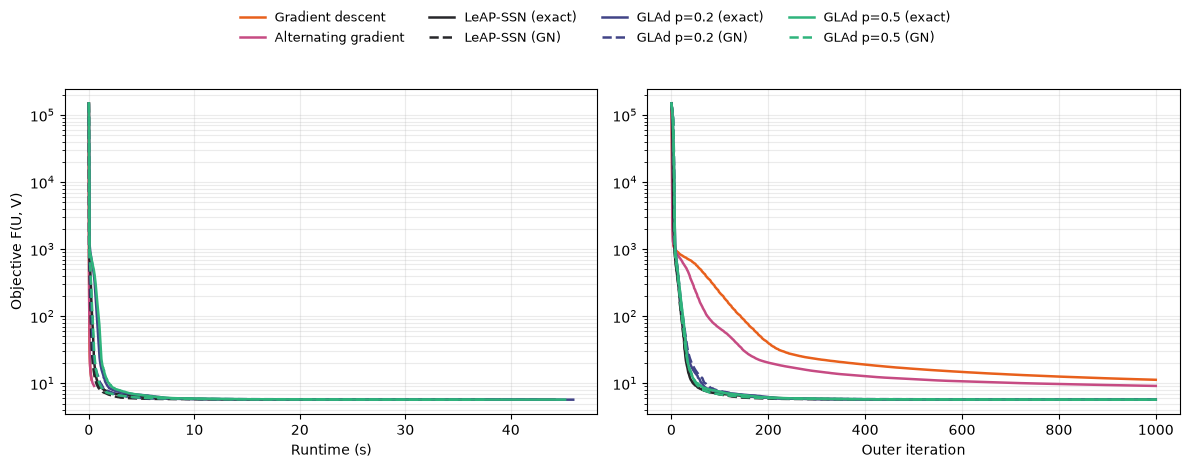

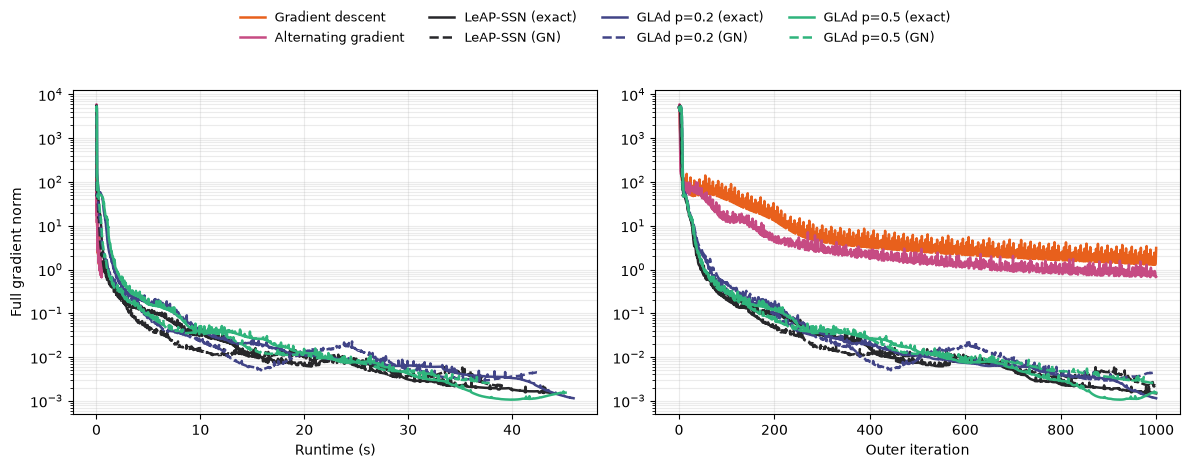

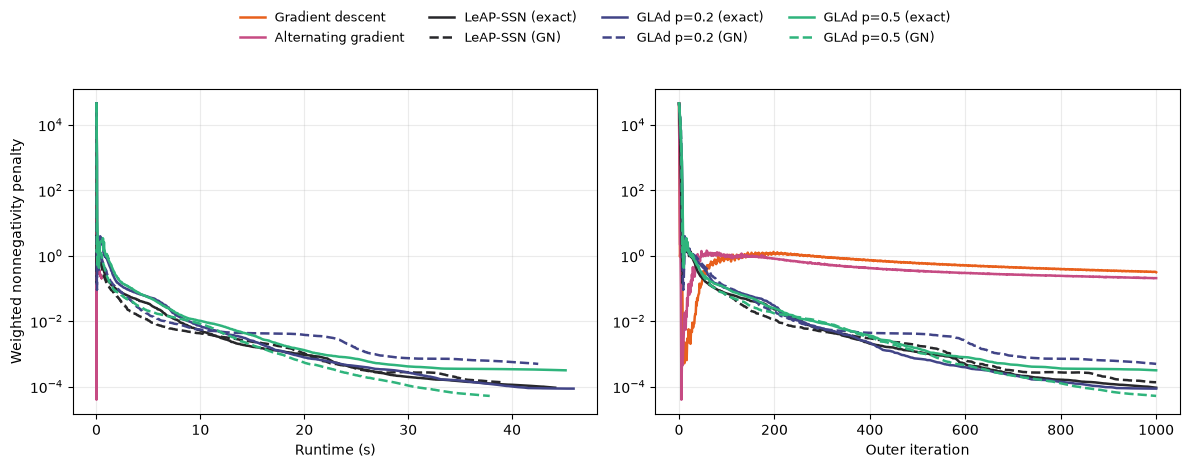

In [7]:
plot_mf_comparison(histories, styles, output_dir=OUTPUT_DIR)